In [5]:
from typing import List
from pydantic import BaseModel, Field

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS

from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, END

In [6]:
import os
from dotenv import load_dotenv, find_dotenv

# .env sits in the repo root (c:\MyCode\RAG), one level above this notebook
load_dotenv(find_dotenv(usecwd=True))

# .env stores the keys in lowercase; ChatGroq and huggingface_hub read the uppercase names
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN") or os.getenv("hf_token", "")

assert os.environ["GROQ_API_KEY"], "groq_api / GROQ_API_KEY missing in .env"
print("GROQ_API_KEY loaded:", os.environ["GROQ_API_KEY"].startswith("gsk_"))

GROQ_API_KEY loaded: True


In [7]:
# Groq LLM - llama-3.3-70b-versatile is no longer served by Groq (404 model_not_found)
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)

# HuggingFace embeddings - runs locally, free
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [8]:
if not os.path.exists("internal_docs.txt"):
    with open("internal_docs.txt", "w", encoding="utf-8") as f:
        f.write("""Our production stack uses several transformer variants.
EfficientFormer is used for on-device vision tasks because of its low latency.
Reformer handles long-document processing thanks to LSH attention and reversible layers.
LLaMA2 powers the internal chat assistant and is fine-tuned on support tickets.
TinyBERT is deployed for intent classification where CPU inference is required.
DistilBERT was evaluated but replaced by TinyBERT due to memory limits.
All models are served through a Triton inference server with dynamic batching.
""")

In [9]:
docs = TextLoader("internal_docs.txt", encoding="utf-8").load()
chunks = RecursiveCharacterTextSplitter(
    chunk_size=500, chunk_overlap=50
).split_documents(docs)

vectorstore = FAISS.from_documents(chunks, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
print(f"Chunks indexed: {len(chunks)}")

Chunks indexed: 2


In [10]:
MAX_ATTEMPTS = 3

class RAGReflectionState(BaseModel):
    question: str
    search_query: str = ""          # rewritten query used for retrieval
    retrieved_docs: List[Document] = []
    answer: str = ""
    reflection: str = ""            # critic feedback
    is_good: bool = False
    attempts: int = 0


# Structured output for the critic -> no fragile string parsing
class Reflection(BaseModel):
    grounded: bool = Field(description="True if every claim in the answer is supported by the context")
    complete: bool = Field(description="True if the answer fully addresses the question using the context")
    feedback: str = Field(description="What is missing or unsupported, and what to search for next")

critic = llm.with_structured_output(Reflection)

In [11]:
def _format_context(docs: List[Document]) -> str:
    return "\n\n".join(d.page_content for d in docs)


# a. Retrieve
def retrieve_docs(state: RAGReflectionState):
    query = state.search_query or state.question
    docs = retriever.invoke(query)
    print(f"🔎 Retrieving with: {query!r} -> {len(docs)} docs")
    return {"retrieved_docs": docs}


# b. Generate answer (uses previous feedback on retries)
def generate_answer(state: RAGReflectionState):
    feedback_block = (
        f"\nA reviewer said your previous answer had this problem:\n{state.reflection}\nFix it.\n"
        if state.attempts > 0 else ""
    )
    prompt = f"""Answer the question using ONLY the context below.
If the context does not contain the answer, say so clearly. Do not use outside knowledge.
{feedback_block}
Context:
{_format_context(state.retrieved_docs)}

Question:
{state.question}
"""
    answer = llm.invoke(prompt).content.strip()
    return {"answer": answer, "attempts": state.attempts + 1}


# c. Self-reflect (critic sees the context too!)
def reflect_on_answer(state: RAGReflectionState):
    prompt = f"""You are a strict reviewer for a RAG system.
Judge the answer ONLY against the given context, not your own knowledge.

Context:
{_format_context(state.retrieved_docs)}

Question: {state.question}

Answer: {state.answer}
"""
    r: Reflection = critic.invoke(prompt)
    print(f"🪞 Attempt {state.attempts}: grounded={r.grounded}, complete={r.complete}")
    return {"reflection": r.feedback, "is_good": r.grounded and r.complete}


# d. Rewrite query using critic feedback (so the retry actually changes something)
def rewrite_query(state: RAGReflectionState):
    prompt = f"""Rewrite the search query to find the missing information.
Original question: {state.question}
Reviewer feedback: {state.reflection}
Return only the new search query, nothing else."""
    new_query = llm.invoke(prompt).content.strip().strip('"')
    return {"search_query": new_query}


# e. Finalizer
def finalize(state: RAGReflectionState):
    return {}

In [12]:
def route_after_reflection(state: RAGReflectionState) -> str:
    if state.is_good or state.attempts >= MAX_ATTEMPTS:
        return "done"
    return "rewriter"


builder = StateGraph(RAGReflectionState)

builder.add_node("retriever", retrieve_docs)
builder.add_node("responder", generate_answer)
builder.add_node("reflector", reflect_on_answer)
builder.add_node("rewriter", rewrite_query)
builder.add_node("done", finalize)

builder.set_entry_point("retriever")
builder.add_edge("retriever", "responder")
builder.add_edge("responder", "reflector")
builder.add_conditional_edges(
    "reflector",
    route_after_reflection,
    {"done": "done", "rewriter": "rewriter"},
)
builder.add_edge("rewriter", "retriever")
builder.add_edge("done", END)

graph = builder.compile()

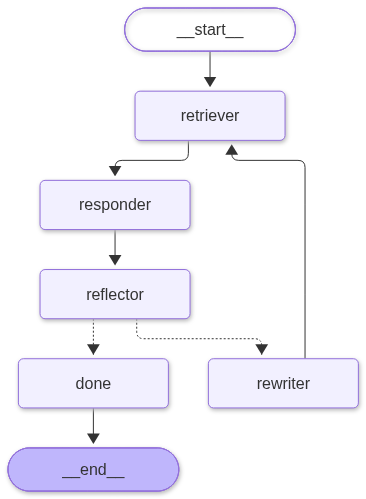

In [13]:
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Diagram render failed (needs internet):", e)

In [14]:
user_query = "What are the transformer variants in production deployments?"
result = graph.invoke(RAGReflectionState(question=user_query))

print("\n🧠 Final Answer:\n", result["answer"])
print("\n🔁 Last Reflection:\n", result["reflection"])
print("✅ Accepted by critic:", result["is_good"])
print("🔄 Total Attempts:", result["attempts"])

🔎 Retrieving with: 'What are the transformer variants in production deployments?' -> 2 docs
🪞 Attempt 1: grounded=True, complete=True

🧠 Final Answer:
 The transformer variants currently deployed in production are:

- EfficientFormer  
- Reformer  
- LLaMA2  
- TinyBERT

🔁 Last Reflection:
 All transformer variants in production deployments are correctly listed.
✅ Accepted by critic: True
🔄 Total Attempts: 1
